In [1]:
import sys, warnings, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
FIG, TAB, PRED = ROOT/"results"/"figures", ROOT/"results"/"tables", ROOT/"results"/"predictions"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
def savefig(name):
    plt.savefig(FIG/f"{name}.png", bbox_inches="tight"); print("saved ->", f"results/figures/{name}.png")
pd.set_option("display.width", 160, "display.max_columns", 40, "display.float_format", lambda v: f"{v:,.3f}")

# 07 · Main ablation: do weekly rainfall lags beat seasonal aggregates?

**Design.** Identical algorithms, identical chronological split (train 1990-2009 / validation 2010-2013 / test 2014-2017),
identical hyper-parameter grids (tuned on validation MAE only), identical state fixed effects. **Only the rainfall representation changes.**

| Code | Representation (all + state one-hot) | Mirrors proposal slide |
|---|---|---|
| F0 | Phase-1 aggregates `IMD_RF`, `IMD_Tmax`, `SD_RF_jun_nov` | baseline `Yield = f(R_t, T_t)` |
| F1 | **Same-source control**: 16-week IMD total + SD of weekly rain, `IMD_Tmax` | isolates *timing* from the *change of data source* |
| F2 | Contemporaneous: rain of the last 4 weeks + last week | "Contemporaneous" |
| F3 | Cumulative: rain summed back 4/8/12/16 weeks | "Cumulative" |
| F4 | 5 phenological-stage sums | stage-aware |
| F5 | **Proposed**: 16 weekly lags `w-16 … w-1` | "Lagged" |
| F6 | F5 + 16 weekly Tmax lags | extension |
| F7 | 16 weekly rainfall **anomalies** (departure from district normal, training-year climatology) | extension |
| F8 | Seasonal-total anomaly | aggregate counterpart of F7 |

**Three forecasting formulations (tiers)** - added because Phase 1 showed that most error is *not* weather:

* **A - weather only (Phase-1 formulation):** predict the yield level from weather + state.
* **B - level + context:** A plus last season's district yield and the mean of the last three seasons (published before the new harvest, so legitimate at forecast time).
* **C - anomaly:** predict the *deviation* from the district's trailing 3-season mean, then add the baseline back. This removes the technological trend and district productivity level, so the model must explain the part of yield that weather can plausibly drive. Errors are always reported in kg/ha of *yield*.

Reference forecasts without any weather are given for calibration. Five seeds for stochastic models; statistics use a district-cluster paired bootstrap.

In [2]:
from src.experiment import *
M = pd.read_csv(TAB/"p2_main_metrics.csv"); P = pd.read_csv(PRED/"p2_main_test_predictions.csv.gz")
N = pd.read_csv(TAB/"p2_naive_baselines.csv")
D = pd.read_csv(ROOT/"data/processed/phase2_lag_features.csv.gz")
parts = split_frame(D)
print(M.groupby(["tier"]).size().to_string()); N[N.split == "test"]

tier
A_weather_only          297
B_level_plus_context    297
C_anomaly               297


,model,split,MAE,RMSE,R2,n
3,Naive: train state mean,test,740.643,918.756,0.125,1470
4,Naive: train district mean,test,641.093,807.045,0.325,1470
5,Naive: persistence (prev-year yield),test,362.291,544.769,0.692,1470


## 1 · Reference points: what do forecasts *without weather* achieve on 2014-2017?

In [3]:
t = parts["test"]
ref = {"Train-state mean": N.query("split=='test' and model=='Naive: train state mean'").iloc[0],
       "Train-district mean": N.query("split=='test' and model=='Naive: train district mean'").iloc[0],
       "Persistence (last year's yield)": N.query("split=='test' and model=='Naive: persistence (prev-year yield)'").iloc[0]}
from src.evaluation import calculate_metrics
ref["District baseline = mean of last 3 seasons"] = pd.Series(calculate_metrics(t[TARGET].values, t[BASE_COL].values))
R = pd.DataFrame({k: v[["MAE", "RMSE", "R2"]] for k, v in ref.items()}).T
R.to_csv(TAB/"p2_reference_forecasts_test.csv"); R

,MAE,RMSE,R2
Train-state mean,740.643,918.756,0.125
Train-district mean,641.093,807.045,0.325
Persistence (last year's yield),362.291,544.769,0.692
District baseline = mean of last 3 seasons,337.178,484.811,0.756


## 2 · Test-set results: every representation × model × tier

In [4]:
T = M[M.split == "test"]
S = T.groupby(["tier", "feature_set", "model"]).agg(MAE=("MAE", "mean"), MAE_sd=("MAE", "std"), RMSE=("RMSE", "mean"), R2=("R2", "mean"), R2_sd=("R2", "std"), n_seeds=("seed", "nunique")).reset_index()
S.to_csv(TAB/"p2_main_summary_test.csv", index=False)
for tier in S.tier.unique():
    print("=" * 20, tier)
    x = S[S.tier == tier].pivot(index="feature_set", columns="model", values="MAE")
    sd = S[S.tier == tier].pivot(index="feature_set", columns="model", values="MAE_sd")
    print((x.round(1).astype(str) + " ± " + sd.round(1).astype(str)).to_string())

==================== A_weather_only
model                           RF        Ridge          XGB
feature_set                                                 
F0_Aggregate_IMD       726.1 ± 0.4  728.3 ± nan  732.4 ± 1.1
F1_Aggregate_IMDgrid   738.3 ± 0.9  727.5 ± nan  732.1 ± 1.0
F2_Contemporaneous     759.8 ± 0.7  729.6 ± nan  748.7 ± 1.4
F3_Cumulative          740.2 ± 0.6  728.4 ± nan  747.4 ± 2.0
F4_Stage               735.0 ± 1.4  727.9 ± nan  735.3 ± 1.2
F5_Lag16               742.6 ± 1.9  727.1 ± nan  741.1 ± 2.7
F6_Lag16_PlusTmaxLags  716.6 ± 3.1  716.5 ± nan  697.2 ± 3.2
F7_Lag16_Anomaly       714.7 ± 1.8  730.1 ± nan  707.0 ± 3.4
F8_Total_Anomaly       754.8 ± 1.2  731.2 ± nan  747.3 ± 1.1
==================== B_level_plus_context
model                           RF        Ridge          XGB
feature_set                                                 
F0_Aggregate_IMD       356.3 ± 1.5  355.5 ± nan  351.3 ± 1.2
F1_Aggregate_IMDgrid   355.4 ± 1.3  354.4 ± nan  354.4 ± 0.4
F2_Cont

saved -> results/figures/p2_07_main_ablation_mae.png


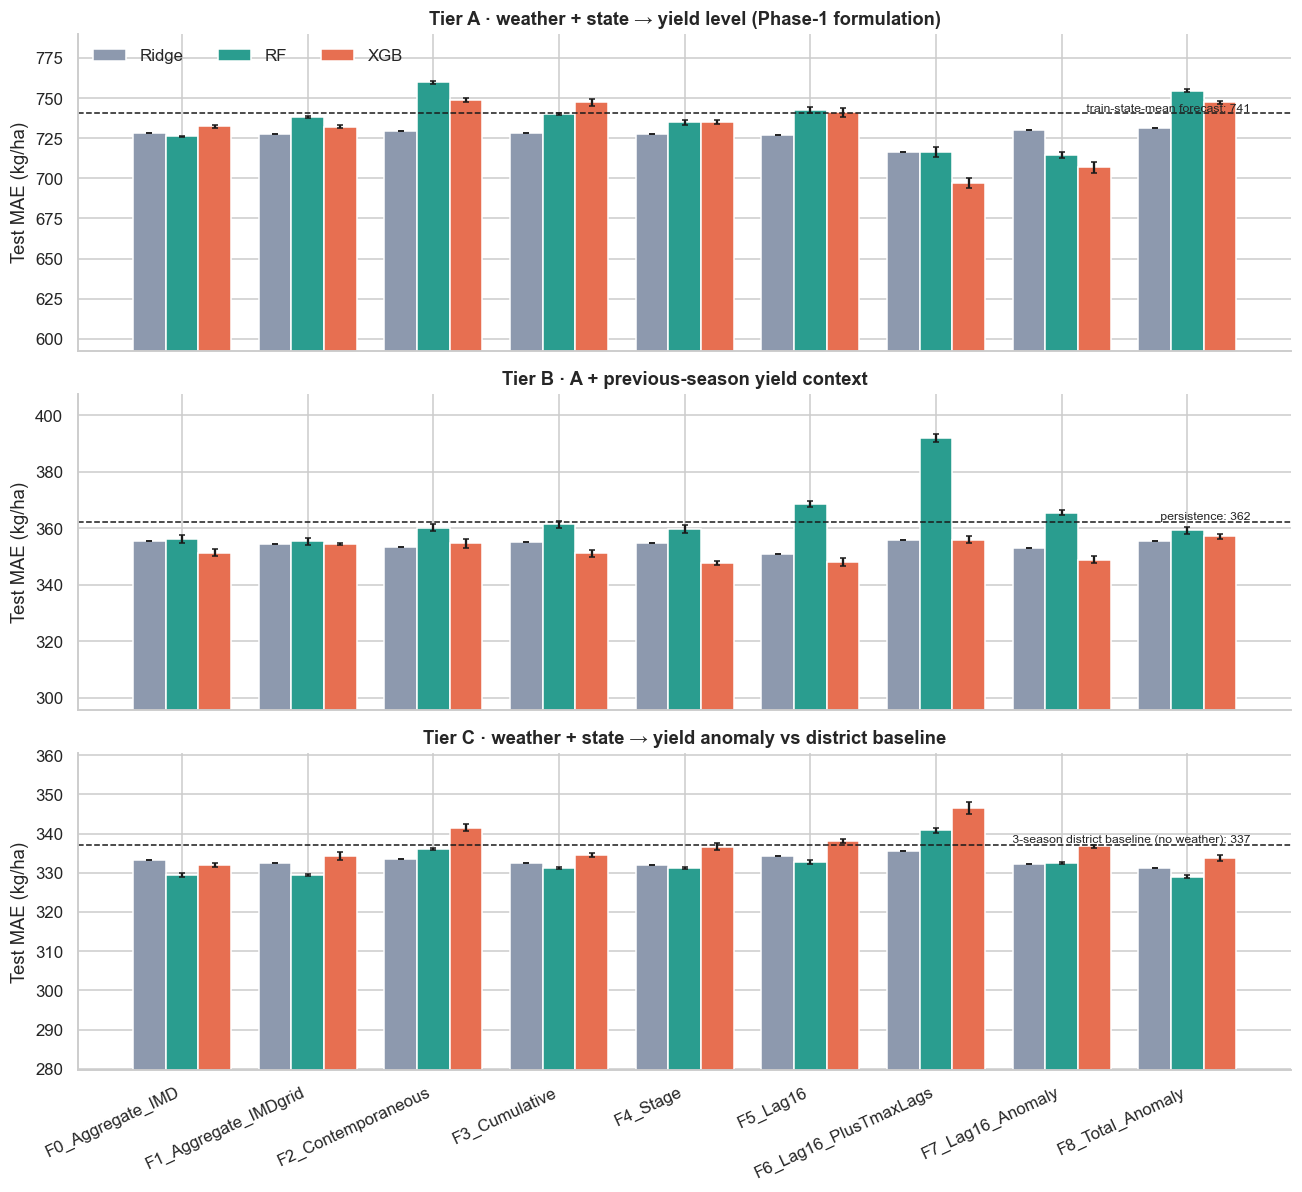

In [5]:
BASE_LINES = {"A_weather_only": ("train-state-mean forecast", ref["Train-state mean"].MAE),
              "B_level_plus_context": ("persistence", ref["Persistence (last year's yield)"].MAE),
              "C_anomaly": ("3-season district baseline (no weather)", ref["District baseline = mean of last 3 seasons"].MAE)}
pal = {"Ridge": "#8d99ae", "RF": "#2a9d8f", "XGB": "#e76f51"}
fig, axs = plt.subplots(3, 1, figsize=(12, 11), sharex=True)
order = list(FEATURE_SETS)
for ax, tier in zip(axs, ["A_weather_only", "B_level_plus_context", "C_anomaly"]):
    s = S[S.tier == tier]
    w = 0.26
    for j, mod in enumerate(["Ridge", "RF", "XGB"]):
        q = s[s.model == mod].set_index("feature_set").loc[order]
        ax.bar(np.arange(len(order)) + (j - 1) * w, q.MAE, w, yerr=q.MAE_sd.fillna(0), color=pal[mod], label=mod, capsize=2)
    lab, v = BASE_LINES[tier]; ax.axhline(v, color="k", ls="--", lw=1); ax.text(len(order) - 0.5, v, f" {lab}: {v:.0f}", va="bottom", ha="right", fontsize=8)
    lo = s.MAE.min(); ax.set_ylim(max(0, lo * 0.85), s.MAE.max() * 1.04)
    ax.set_ylabel("Test MAE (kg/ha)"); ax.set_title({"A_weather_only": "Tier A · weather + state → yield level (Phase-1 formulation)",
        "B_level_plus_context": "Tier B · A + previous-season yield context", "C_anomaly": "Tier C · weather + state → yield anomaly vs district baseline"}[tier])
axs[0].legend(ncol=3, frameon=False, loc="upper left"); axs[2].set_xticks(range(len(order))); axs[2].set_xticklabels(order, rotation=25, ha="right")
plt.tight_layout(); savefig("p2_07_main_ablation_mae"); plt.show()

## 3 · Is the best representation *statistically* better? Paired cluster bootstrap

For each comparison we average the five seeds' predictions into one forecast per district-year, compute the paired difference in
absolute error, and resample **districts** (4,000 draws) because the four test years of a district are not independent.
`delta_mae < 0` means the first representation is better. Comparisons are pre-specified: the proposed lag representation against
(i) the Phase-1 baseline (F0), (ii) the same-source aggregate (F1) - the cleanest test of *timing* - and (iii) the cumulative/stage/contemporaneous
ablations; the anomaly lag vector against the anomaly total.

In [6]:
E = mean_seed_predictions(P)
def err(tier, fs, mod):
    x = P[(P.tier == tier) & (P.feature_set == fs) & (P.model == mod)]
    x = x.groupby(["stable_geographic_id", "Year"], as_index=False).agg(Actual=("Actual", "first"), Predicted=("Predicted", "mean"))
    x["ae"] = (x.Actual - x.Predicted).abs(); return x.set_index(["stable_geographic_id", "Year"])
PAIRS = [("F5_Lag16", "F0_Aggregate_IMD"), ("F5_Lag16", "F1_Aggregate_IMDgrid"), ("F5_Lag16", "F3_Cumulative"), ("F5_Lag16", "F4_Stage"),
         ("F5_Lag16", "F2_Contemporaneous"), ("F4_Stage", "F1_Aggregate_IMDgrid"), ("F7_Lag16_Anomaly", "F8_Total_Anomaly"),
         ("F6_Lag16_PlusTmaxLags", "F5_Lag16"), ("F1_Aggregate_IMDgrid", "F0_Aggregate_IMD")]
rows = []
for tier in ["A_weather_only", "B_level_plus_context", "C_anomaly"]:
    for mod in ["RF", "XGB", "Ridge"]:
        for a, b in PAIRS:
            ea, eb = err(tier, a, mod), err(tier, b, mod)
            idx = ea.index.intersection(eb.index)
            r = paired_cluster_bootstrap(ea.loc[idx, "ae"].values, eb.loc[idx, "ae"].values, np.array([i[0] for i in idx]))
            rows.append(dict(tier=tier, model=mod, A=a, B=b, **r))
BT = pd.DataFrame(rows); BT.to_csv(TAB/"p2_main_paired_bootstrap.csv", index=False)
BT[(BT.A == "F5_Lag16") & (BT.B.isin(["F0_Aggregate_IMD", "F1_Aggregate_IMDgrid"]))]

,tier,model,A,B,delta_mae,ci_lo,ci_hi,p_boot
0,A_weather_only,RF,F5_Lag16,F0_Aggregate_IMD,16.147,0.248,32.168,0.048
1,A_weather_only,RF,F5_Lag16,F1_Aggregate_IMDgrid,4.156,-9.955,18.137,0.575
9,A_weather_only,XGB,F5_Lag16,F0_Aggregate_IMD,8.268,-5.779,22.172,0.249
10,A_weather_only,XGB,F5_Lag16,F1_Aggregate_IMDgrid,8.090,-2.128,18.720,0.123
18,A_weather_only,Ridge,F5_Lag16,F0_Aggregate_IMD,-1.164,-3.719,1.307,0.358
19,A_weather_only,Ridge,F5_Lag16,F1_Aggregate_IMDgrid,-0.416,-2.493,1.655,0.686
27,B_level_plus_context,RF,F5_Lag16,F0_Aggregate_IMD,11.868,6.317,18.039,0.000
28,B_level_plus_context,RF,F5_Lag16,F1_Aggregate_IMDgrid,12.719,7.252,18.785,0.000
36,B_level_plus_context,XGB,F5_Lag16,F0_Aggregate_IMD,-3.835,-8.862,1.259,0.142
37,B_level_plus_context,XGB,F5_Lag16,F1_Aggregate_IMDgrid,-6.832,-12.156,-1.396,0.013


saved -> results/figures/p2_07_paired_bootstrap_forest.png


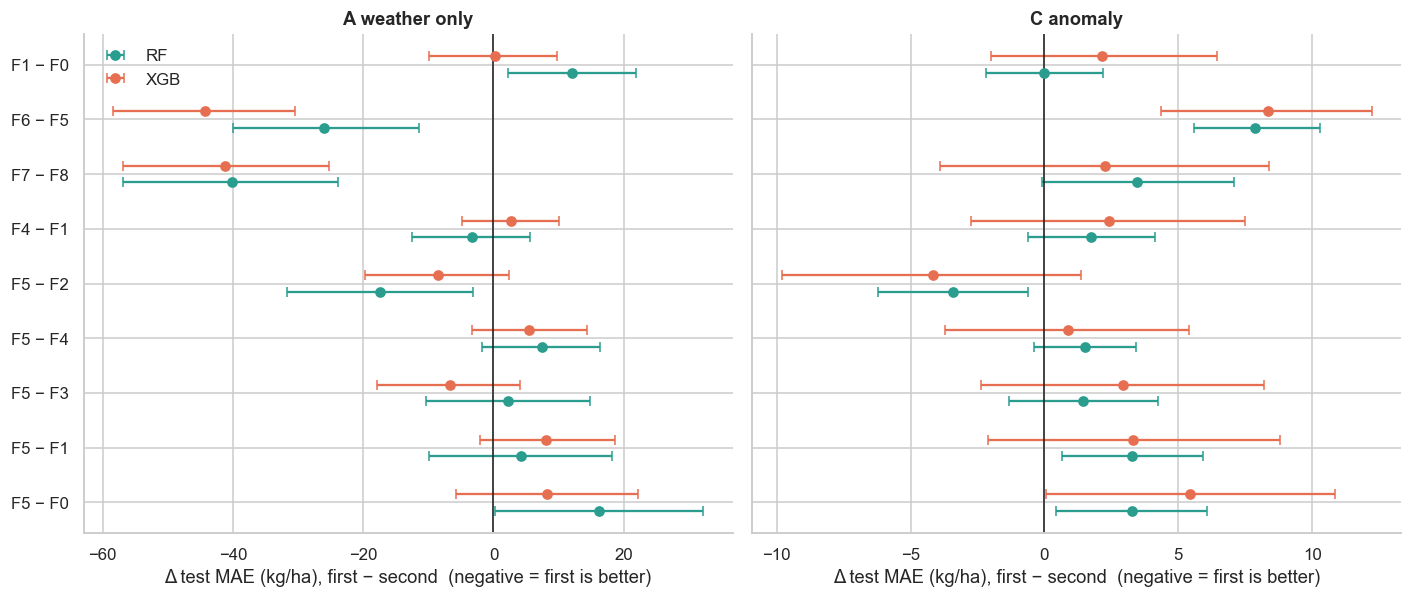

In [7]:
sub = BT[(BT.model.isin(["RF", "XGB"])) & (BT.tier.isin(["A_weather_only", "C_anomaly"]))].copy()
sub["cmp"] = sub.A.str.split("_").str[0] + " − " + sub.B.str.split("_").str[0]
fig, axs = plt.subplots(1, 2, figsize=(13, 5.6), sharey=True)
for ax, tier in zip(axs, ["A_weather_only", "C_anomaly"]):
    s = sub[sub.tier == tier]; ylab = list(dict.fromkeys(s.cmp));
    for k, mod in enumerate(["RF", "XGB"]):
        q = s[s.model == mod].set_index("cmp").loc[ylab]; y = np.arange(len(ylab)) + (k - .5) * .3
        ax.errorbar(q.delta_mae, y, xerr=[q.delta_mae - q.ci_lo, q.ci_hi - q.delta_mae], fmt="o", color=pal[mod], capsize=3, label=mod)
    ax.axvline(0, color="k", lw=1); ax.set_yticks(range(len(ylab))); ax.set_yticklabels(ylab); ax.invert_yaxis()
    ax.set_xlabel("Δ test MAE (kg/ha), first − second  (negative = first is better)"); ax.set_title(tier.replace("_", " "))
axs[0].legend(frameon=False); plt.tight_layout(); savefig("p2_07_paired_bootstrap_forest"); plt.show()

## 4 · Relative gain of each representation over the same-source aggregate (F1), tier C and A

saved -> results/figures/p2_07_relative_mae_heatmap.png


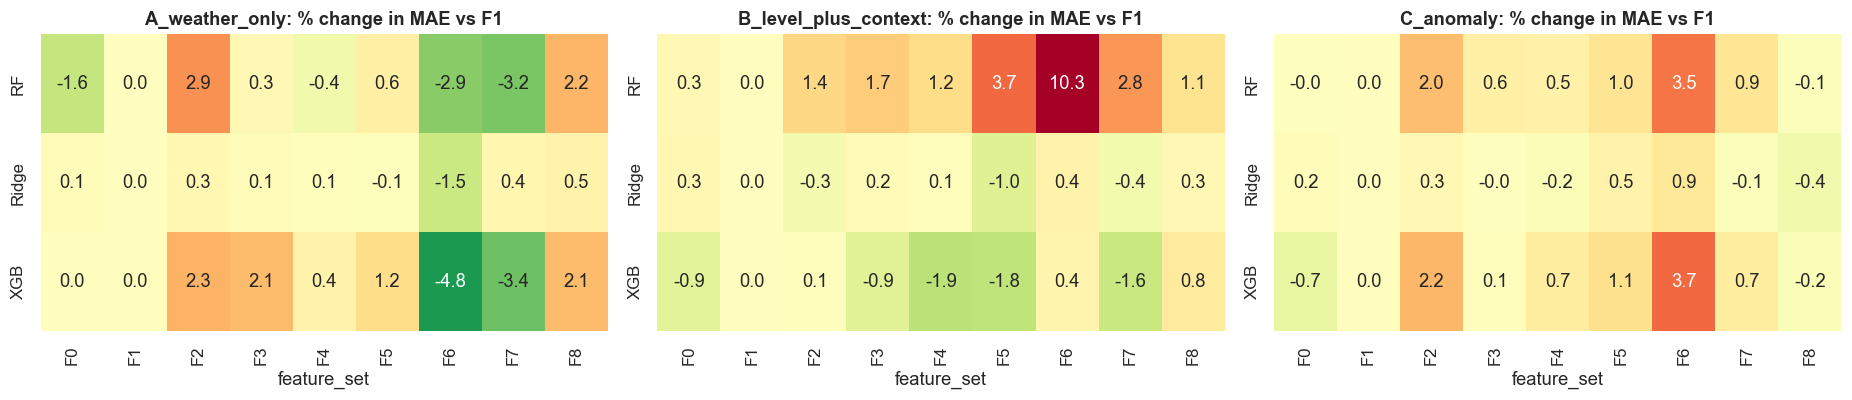

In [8]:
piv = S.pivot_table(index=["tier", "model"], columns="feature_set", values="MAE")
rel = (piv.div(piv["F1_Aggregate_IMDgrid"], axis=0) - 1) * 100
fig, axs = plt.subplots(1, 3, figsize=(17, 3.8))
for ax, tier in zip(axs, ["A_weather_only", "B_level_plus_context", "C_anomaly"]):
    sns.heatmap(rel.loc[tier][order], annot=True, fmt=".1f", cmap="RdYlGn_r", center=0, vmin=-6, vmax=6, cbar=False, ax=ax)
    ax.set_title(f"{tier}: % change in MAE vs F1"); ax.set_xticklabels([c.split("_")[0] for c in order]); ax.set_ylabel("")
plt.tight_layout(); savefig("p2_07_relative_mae_heatmap"); plt.show()

## 5 · Reproducing Phase 1 and the value of the new weather source

In [9]:
p1 = pd.read_csv(TAB/"phase1_metrics.csv").query("split=='test'")[["model", "MAE", "RMSE", "R2"]]
print("Phase-1 published test metrics (src/models.py, notebook 03):"); print(p1.to_string(index=False))
x = S[(S.tier == "A_weather_only") & (S.feature_set == "F0_Aggregate_IMD") & S.model.isin(["RF", "XGB"])][["model", "MAE", "RMSE", "R2"]]
print("\nRe-run inside the Phase-2 engine (5 seeds, mean):"); print(x.to_string(index=False))

Phase-1 published test metrics (src/models.py, notebook 03):
        model     MAE    RMSE    R2
Random Forest 727.194 914.197 0.133
      XGBoost 732.229 921.292 0.120

Re-run inside the Phase-2 engine (5 seeds, mean):
model     MAE    RMSE    R2
   RF 726.120 913.026 0.135
  XGB 732.366 922.172 0.118


## 6 · Where do the errors live? Residual structure of the best tier-C and tier-A models

saved -> results/figures/p2_07_best_models_diagnostics.png


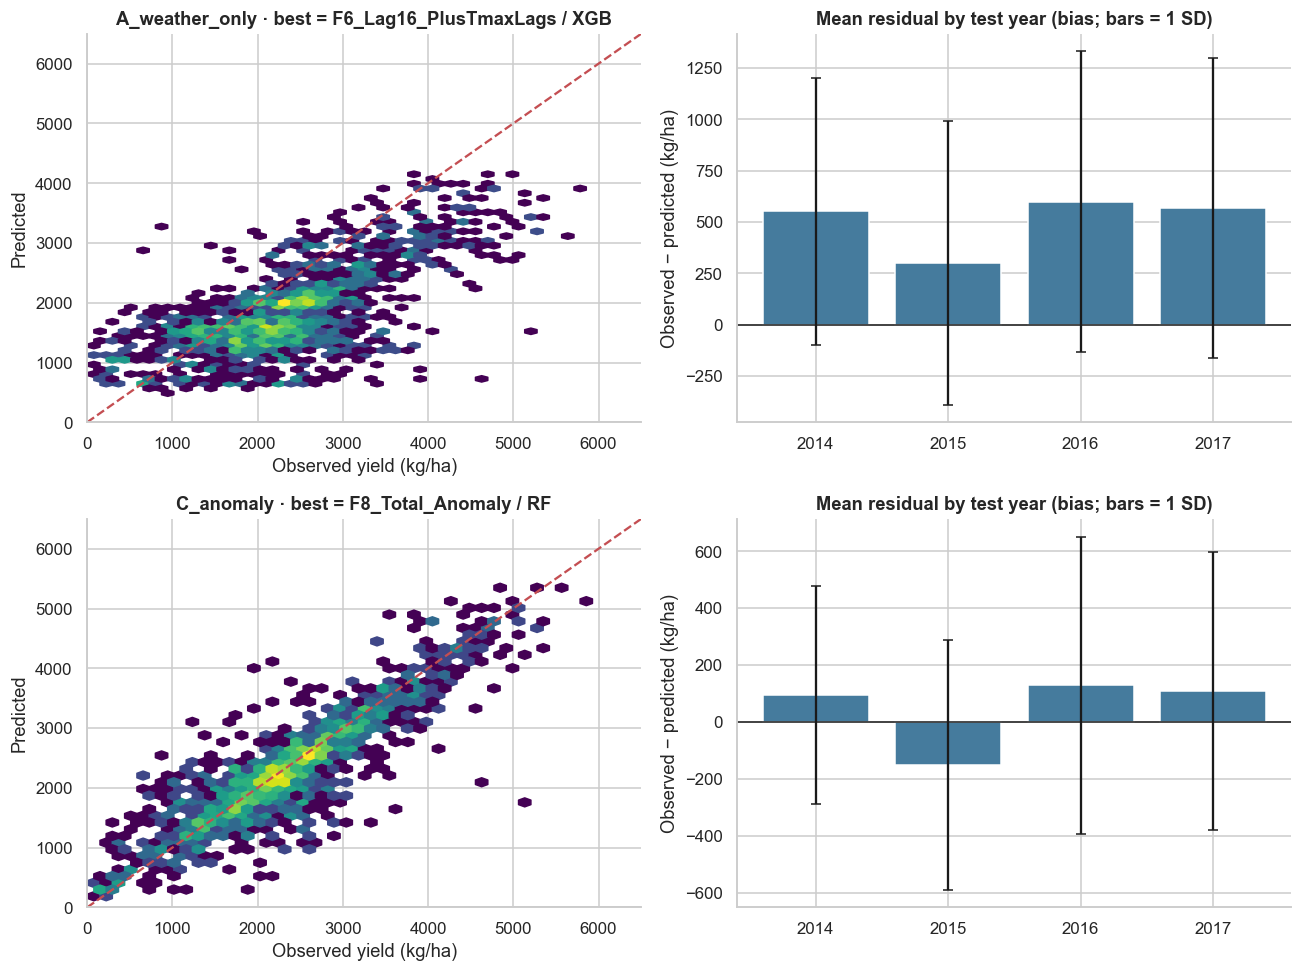

In [10]:
def best(tier):
    s = S[(S.tier == tier) & S.model.isin(["RF", "XGB", "Ridge"])].sort_values("MAE").iloc[0]; return s.feature_set, s.model
fig, axs = plt.subplots(2, 2, figsize=(12, 9))
for r_, tier in enumerate(["A_weather_only", "C_anomaly"]):
    fs, mod = best(tier); e = err(tier, fs, mod).reset_index()
    ax = axs[r_, 0]; ax.hexbin(e.Actual, e.Predicted, gridsize=40, bins="log", cmap="viridis", mincnt=1); lim = [0, 6500]; ax.plot(lim, lim, "r--"); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("Observed yield (kg/ha)"); ax.set_ylabel("Predicted"); ax.set_title(f"{tier} · best = {fs} / {mod}")
    ax = axs[r_, 1]; e["resid"] = e.Actual - e.Predicted; g = e.groupby("Year").resid.agg(["mean", "std"])
    ax.bar(g.index, g["mean"], yerr=g["std"], color="#457b9d", capsize=3); ax.axhline(0, color="k", lw=1)
    ax.set_title("Mean residual by test year (bias; bars = 1 SD)"); ax.set_ylabel("Observed − predicted (kg/ha)"); ax.set_xticks(g.index)
plt.tight_layout(); savefig("p2_07_best_models_diagnostics"); plt.show()

In [11]:
print("Tier A / best model: test-period mean bias (kg/ha):")
fs, mod = best("A_weather_only"); e = err("A_weather_only", fs, mod); print(fs, mod, " bias =", round((e.Actual - e.Predicted).mean(), 1))
print("Tier C / best model:")
fs, mod = best("C_anomaly"); e = err("C_anomaly", fs, mod); print(fs, mod, " bias =", round((e.Actual - e.Predicted).mean(), 1))
tr_mean, te_mean = parts["train"][TARGET].mean(), parts["test"][TARGET].mean()
print(f"mean yield train {tr_mean:.0f} vs test {te_mean:.0f} kg/ha  (+{te_mean/tr_mean*100-100:.0f}%)  -> the level shift that tier A cannot see")

Tier A / best model: test-period mean bias (kg/ha):
F6_Lag16_PlusTmaxLags XGB  bias = 507.1
Tier C / best model:


F8_Total_Anomaly RF  bias = 47.8
mean yield train 1793 vs test 2363 kg/ha  (+32%)  -> the level shift that tier A cannot see


### Take-aways of notebook 07
The numbers above are computed, not asserted. Read them together with the paired-bootstrap table:
whether the lag representation (F5) improves on the same-source aggregate (F1) and on the stage/cumulative ablations is answered
there with confidence intervals. The decisive controls (shuffled week order, misaligned windows, window length, rolling origin) are in notebook 08.